<a href="https://colab.research.google.com/github/GiresseTianjanahary/PM25_model_predict/blob/main/Pollution_vao2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [ ]:
from google.colab import files
from google.colab import drive

In [ ]:
uploaded = files.upload()

Saving Donnees Pollution Giresse.xlsx to Donnees Pollution Giresse.xlsx
Saving donnee hebdo pollution.xlsx to donnee hebdo pollution.xlsx


In [ ]:
data = pd.read_excel("Donnees Pollution Giresse.xlsx")
print(data.head())

        Date      PM2.5
0 2021-01-01   4.281306
1 2021-01-02   5.252139
2 2021-01-03   6.073264
3 2021-01-04   7.353806
4 2021-01-05  18.849083


In [ ]:
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"])
    data = data.set_index("Date")

In [ ]:
series = data["PM2.5"].dropna()

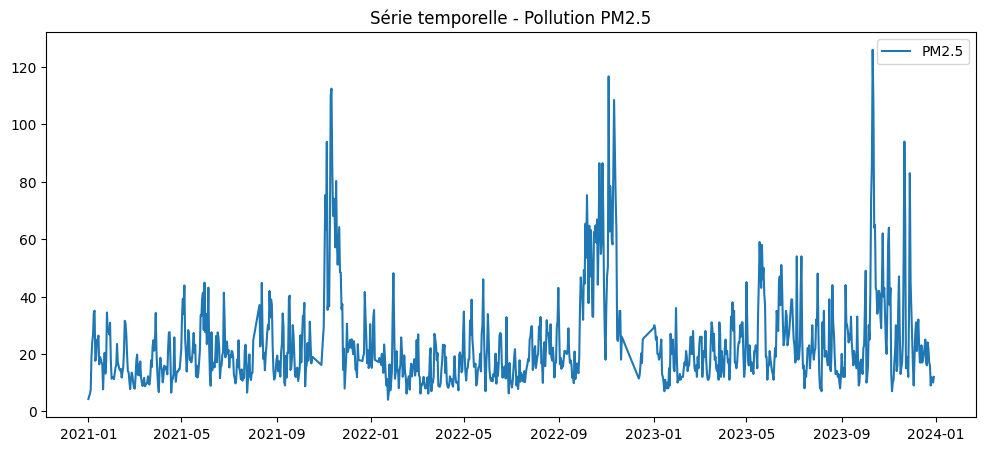

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(series, label="PM2.5")
plt.title("Série temporelle - Pollution PM2.5")
plt.legend()
plt.show()

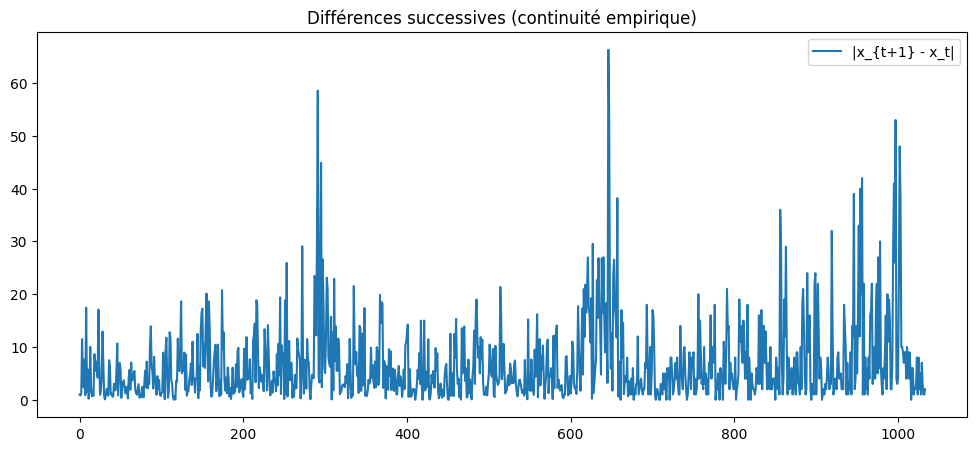

Moyenne des différences successives : 6.805783001366671
Max des différences successives : 66.31


In [ ]:
diffs = np.abs(np.diff(series))
plt.figure(figsize=(12,5))
plt.plot(diffs, label="|x_{t+1} - x_t|")
plt.title("Différences successives (continuité empirique)")
plt.legend()
plt.show()

print("Moyenne des différences successives :", np.mean(diffs))
print("Max des différences successives :", np.max(diffs))

In [ ]:
# Test ADF
adf_result = adfuller(series)
print("\n=== Test ADF ===")
print(f"Statistique ADF : {adf_result[0]}")
print(f"p-value : {adf_result[1]} (p < 0.05 -> stationnaire)")


=== Test ADF ===
Statistique ADF : -4.046264825779079
p-value : 0.0011867183598740453 (p < 0.05 -> stationnaire)


In [ ]:
kpss_result, p_value, lags, crit = kpss(series, regression='c', nlags="auto")
print("\n=== Test KPSS ===")
print(f"Statistique KPSS : {kpss_result}")
print(f"p-value : {p_value} (p > 0.05 -> stationnaire)")


=== Test KPSS ===
Statistique KPSS : 0.40273164975889963
p-value : 0.07597773717288808 (p > 0.05 -> stationnaire)


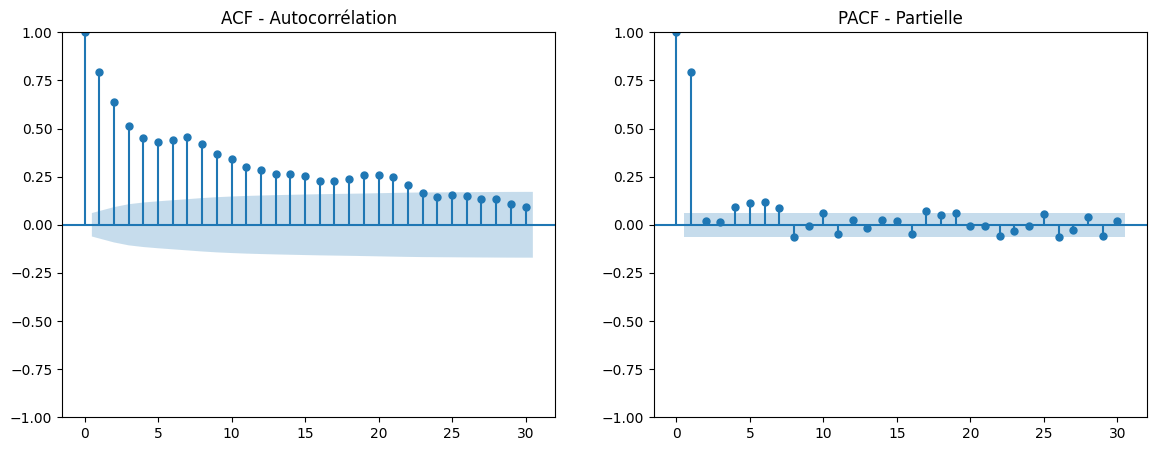

In [ ]:
# 4. Autocorrélation
# -----------------------------
fig, axes = plt.subplots(1,2, figsize=(14,5))
plot_acf(series, ax=axes[0], lags=30)
axes[0].set_title("ACF - Autocorrélation")
plot_pacf(series, ax=axes[1], lags=30)
axes[1].set_title("PACF - Partielle")
plt.show()

In [ ]:
%pip install ruptures

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.8 MB/s eta 0:00:00


In [ ]:
import ruptures as rpt
from sklearn.preprocessing import RobustScaler

In [ ]:
s = series
s = s[~np.isinf(s)]  # nettoyage minimal

# --- 2) Standardisation ---
scaler = RobustScaler()
x = scaler.fit_transform(s.values.reshape(-1,1)).ravel()


Beta = 3.47 → Nombre de ruptures détectées : 12
Beta = 6.94 → Nombre de ruptures détectées : 4
Beta = 13.88 → Nombre de ruptures détectées : 2
Beta = 34.71 → Nombre de ruptures détectées : 0


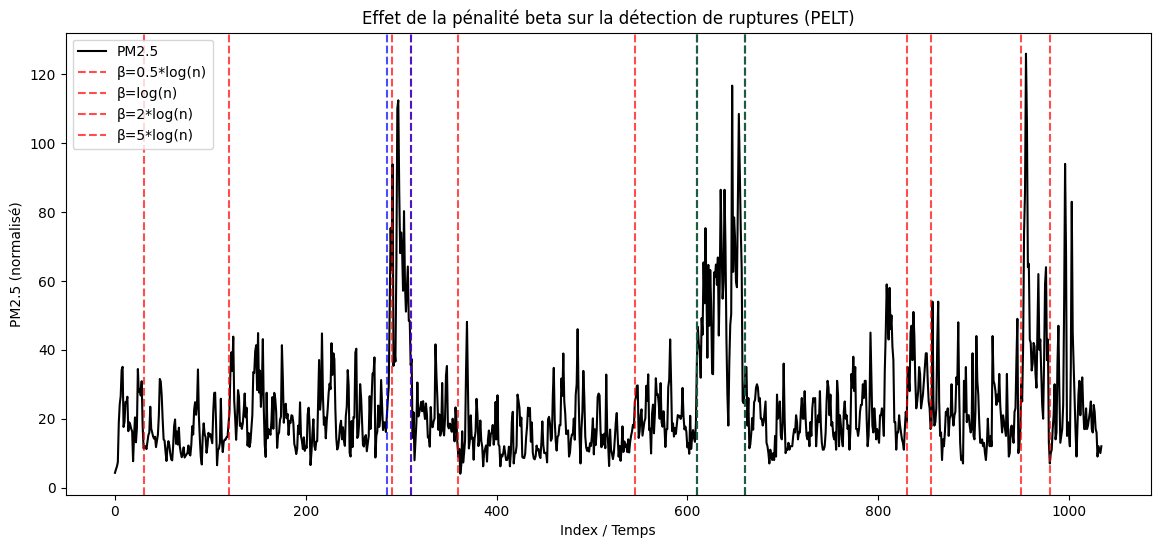

In [ ]:
# --- 3) Paramètres PELT ---
# fonction de coût RBF : capte moyenne/variance/tendance
model = "rbf"

# Différentes valeurs de beta pour tester l'effet
betas = [0.5*np.log(len(x)), np.log(len(x)), 2*np.log(len(x)), 5*np.log(len(x))]

plt.figure(figsize=(14,6))
plt.plot(s.values, label="PM2.5", color="black")

colors = ["red", "blue", "green", "orange"]

for i, beta in enumerate(betas):
    algo = rpt.Pelt(model=model, min_size=10).fit(x)
    bkps = algo.predict(pen=beta)

    # Tracer les ruptures
    for b in bkps[:-1]:  # ignorer dernier point (fin de série)
        plt.axvline(b, linestyle="--", color=colors[i], alpha=0.7)

    print(f"Beta = {beta:.2f} → Nombre de ruptures détectées : {len(bkps)-1}")

plt.title("Effet de la pénalité beta sur la détection de ruptures (PELT)")
plt.xlabel("Index / Temps")
plt.ylabel("PM2.5 (normalisé)")
plt.legend(["PM2.5", "β=0.5*log(n)", "β=log(n)", "β=2*log(n)", "β=5*log(n)"])
plt.show()


In [ ]:
!pip install ipywidgets ruptures --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 65.8 MB/s eta 0:00:00


In [ ]:
from ipywidgets import interact

In [ ]:
def plot_pelet(beta_factor=1.0):
    beta = beta_factor * np.log(len(x))

    algo = rpt.Pelt(model="rbf", min_size=10).fit(x)
    bkps = algo.predict(pen=beta)

    plt.figure(figsize=(14,6))
    plt.plot(s.values, label="PM2.5", color="black")

    for b in bkps[:-1]:
        plt.axvline(b, color="red", linestyle="--", alpha=0.7)

    plt.title(f"Détection de ruptures avec PELT (beta={beta:.2f})")
    plt.xlabel("Index / Temps")
    plt.ylabel("PM2.5 (normalisé)")
    plt.show()

    print(f"Nombre de ruptures détectées : {len(bkps)-1}")

# --- 4) Slider interactif ---
interact(plot_pelet, beta_factor=(0.1, 5.0, 0.01))

interactive(children=(FloatSlider(value=1.0, description='beta_factor', max=5.0, min=0.1, step=0.01), Output()…

<function __main__.plot_pelet(beta_factor=1.0)>

In [ ]:
# --- 3) Pré-calcul du nombre de ruptures pour une plage de beta ---
n=len(x)
beta_factors = np.linspace(0.1, 5.0, 50)
rupture_counts = []

for bf in beta_factors:
    beta = bf * np.log(n)
    algo = rpt.Pelt(model="rbf", min_size=10).fit(x)
    bkps = algo.predict(pen=beta)
    rupture_counts.append(len(bkps)-1)

# --- 4) Fonction interactive pour visualiser ruptures ---
def interactive_pelet(beta_factor=1.0):
    beta = beta_factor * np.log(n)

    # Détection des ruptures
    algo = rpt.Pelt(model="rbf", min_size=10).fit(x)
    bkps = algo.predict(pen=beta)

    # --- Figure 1 : série avec ruptures ---
    plt.figure(figsize=(14,6))
    plt.plot(s.values, label="PM2.5", color="black")
    for b in bkps[:-1]:
        plt.axvline(b, color="red", linestyle="--", alpha=0.7)
    plt.title(f"PELT : beta={beta:.2f} → {len(bkps)-1} ruptures détectées")
    plt.xlabel("Index / Temps")
    plt.ylabel("PM2.5 (normalisé)")
    plt.show()

    print(f"Nombre de ruptures détectées : {len(bkps)-1}")

    # --- Figure 2 : nombre de ruptures vs beta ---
    plt.figure(figsize=(10,4))
    plt.plot(beta_factors*np.log(n), rupture_counts, marker='o')
    plt.axvline(beta, color='red', linestyle='--', alpha=0.7)
    plt.title("Nombre de ruptures détectées en fonction de beta")
    plt.xlabel("Beta")
    plt.ylabel("Nombre de ruptures")
    plt.show()

# --- 5) Slider interactif ---
interact(interactive_pelet, beta_factor=(0.1, 5.0, 0.05))

interactive(children=(FloatSlider(value=1.0, description='beta_factor', max=5.0, min=0.1, step=0.05), Output()…

<function __main__.interactive_pelet(beta_factor=1.0)>

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from statsmodels.stats.diagnostic import linear_reset


# --- 1. Vérification de la linéarité ---
def check_linearity(y, significance=0.05, degree_poly=2):
    """
    Vérifie si une série est linéaire ou non-linéaire.
    """
    t = np.arange(len(y))
    X = sm.add_constant(t)
    model = sm.OLS(y, X, missing="drop").fit()

    # Test RESET
    try:
        reset_test = linear_reset(model, power=2, use_f=True)
        p_value = reset_test.pvalue
    except:
        p_value = 1.0

    # Comparaison avec polynôme
    y_valid = y[~np.isnan(y)]
    t_valid = np.arange(len(y_valid)).reshape(-1, 1)

    linreg = LinearRegression().fit(t_valid, y_valid)
    y_pred_lin = linreg.predict(t_valid)

    poly = PolynomialFeatures(degree=degree_poly)
    X_poly = poly.fit_transform(t_valid)
    polyreg = LinearRegression().fit(X_poly, y_valid)
    y_pred_poly = polyreg.predict(X_poly)

    rmse_lin = np.sqrt(mean_squared_error(y_valid, y_pred_lin))
    rmse_poly = np.sqrt(mean_squared_error(y_valid, y_pred_poly))

    #if (p_value < significance) or (rmse_poly < rmse_lin * 0.9):
    if (rmse_poly < rmse_lin * 0.9):
        diagnostic = "non-linéaire"
    else:
        diagnostic = "linéaire"

    return diagnostic


# --- 2. Sélection automatique du modèle Kalman ---
def choose_kalman_model(y):
    """
    Choisit automatiquement un modèle de Kalman en fonction de la structure de la série.
    """
    # Si série semble stationnaire -> modèle "local level"
    if np.allclose(np.diff(y.dropna()), 0, atol=1e-2):
        return sm.tsa.UnobservedComponents(y, level="local level")

    # Si tendance -> "local linear trend"
    if np.abs(np.mean(np.diff(y.dropna()))) > 1e-2:
        return sm.tsa.UnobservedComponents(y, level="local linear trend")

    # Sinon -> tendance + saisonnalité (par défaut saisonnalité = 12)
    return sm.tsa.UnobservedComponents(y, level="local linear trend", seasonal=12)


# --- 3. Pipeline d’imputation ---
def impute_series(y):
    """
    Impute une série temporelle à partir du diagnostic de linéarité.
    """
    y = pd.Series(y).copy()
    diagnostic = check_linearity(y.values)
    print("Diagnostic :", diagnostic)

    if diagnostic == "linéaire":
        print("→ Imputation par interpolation linéaire")
        y_imputed = y.interpolate(method="linear")

    else:
        print("→ Imputation par filtre de Kalman (choix automatique du modèle)")
        mod = choose_kalman_model(y)
        res = mod.fit(disp=False)
        y_imputed = pd.Series(res.fittedvalues, index=y.index)

    return y_imputed


# --- 4. Lecture d'un fichier Excel ---
def load_and_impute_excel(file_path, sheet_name=0, col_name=None):
    """
    Lit un fichier Excel et impute les valeurs manquantes d'une série temporelle.

    file_path : chemin du fichier Excel
    sheet_name : nom ou index de la feuille (par défaut 0)
    col_name : nom de la colonne contenant la série
    """
    df = pd.read_excel(file_path, sheet_name=sheet_name)

    if col_name is None:
        # On suppose que la première colonne numérique est la série
        col_name = df.select_dtypes(include=[np.number]).columns[0]

    print(f"Colonne utilisée : {col_name}")
    y = df[col_name]

    y_imputed = impute_series(y)

    # Ajout d'une colonne imputée dans le DataFrame
    df[col_name + "_imputed"] = y_imputed

    return df


In [ ]:
load_and_impute_excel("Donnees Pollution Giresse.xlsx", sheet_name=0, col_name="PM2.5")

Colonne utilisée : PM2.5
Diagnostic : linéaire
→ Imputation par interpolation linéaire


,Date,PM2.5,PM2.5_imputed
0,2021-01-01,4.281306,4.281306
1,2021-01-02,5.252139,5.252139
2,2021-01-03,6.073264,6.073264
3,2021-01-04,7.353806,7.353806
4,2021-01-05,18.849083,18.849083
...,...,...,...
1090,2023-12-27,11.000000,11.000000
1091,2023-12-28,10.000000,10.000000
1092,2023-12-29,12.000000,12.000000
1093,2023-12-30,NaN,12.000000


In [ ]:
!pip install fastdtw

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for fastdtw: filename=fastdtw-0.3.4-cp312-cp312-linux_x86_64.whl size=567858 sha256=7b451e1596b3a9dd20ab507a77beef7a986c8aa56a400b5338701721c15ef230
  Stored in directory: /root/.cache/pip/wheels/ab/d0/26/b82cb0f49ae73e5e6bba4e8462fff2c9851d7bd2ec64f8891e
Successfully built fastdtw


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.stats.diagnostic import linear_reset
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean
import statsmodels.api as sm

# ---------------------------
# 1. Vérification de linéarité
# ---------------------------
def check_linearity(y, significance=0.05, degree_poly=2):
    t = np.arange(len(y))
    X = sm.add_constant(t)
    model = sm.OLS(y, X, missing="drop").fit()
    try:
        reset_test = linear_reset(model, power=2, use_f=True)
        p_value = reset_test.pvalue
    except:
        p_value = 1.0

    y_valid = y[~np.isnan(y)]
    t_valid = np.arange(len(y_valid)).reshape(-1, 1)
    linreg = LinearRegression().fit(t_valid, y_valid)
    y_pred_lin = linreg.predict(t_valid)
    poly = PolynomialFeatures(degree=degree_poly)
    X_poly = poly.fit_transform(t_valid)
    polyreg = LinearRegression().fit(X_poly, y_valid)
    y_pred_poly = polyreg.predict(X_poly)
    rmse_lin = np.sqrt(mean_squared_error(y_valid, y_pred_lin))
    rmse_poly = np.sqrt(mean_squared_error(y_valid, y_pred_poly))

    if (p_value < significance) or (rmse_poly < rmse_lin * 0.9):
        return "non-linéaire"
    else:
        return "linéaire"

# ---------------------------
# 2. Imputation automatique
# ---------------------------
def impute_series_auto(y):
    y = pd.Series(y).copy()
    diagnostic = check_linearity(y.values)
    print("Diagnostic de linéarité :", diagnostic)

    if diagnostic == "linéaire":
        print("→ Imputation par interpolation linéaire")
        y_imputed = y.interpolate(method="linear").ffill().bfill()
    else:
        print("→ Imputation par Kalman (local linear trend)")
        mod = sm.tsa.UnobservedComponents(y, level="local linear trend")
        res = mod.fit(disp=False)
        y_imputed = pd.Series(res.fittedvalues, index=y.index)

    return y_imputed

# ---------------------------
# 3. Evaluation avec DTW
# ---------------------------
def make_eval_mask(y, frac=0.15, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    idx_obs = np.where(~np.isnan(y))[0]
    n_eval = max(1, int(len(idx_obs) * frac))
    eval_idx = np.random.choice(idx_obs, size=n_eval, replace=False)
    mask = np.zeros(len(y), dtype=bool)
    mask[eval_idx] = True
    return mask

#def dtw_distance(a, b, normalize=True):
 #   a = np.asarray(a, dtype=float).ravel()
  #  b = np.asarray(b, dtype=float).ravel()
   # if normalize:
    #    scaler = StandardScaler()
     #   stacked = np.concatenate([a[~np.isnan(a)], b[~np.isnan(b)]]).reshape(-1,1)
      #  scaler.fit(stacked)
       # a = np.where(np.isnan(a), np.nan, scaler.transform(a.reshape(-1,1)))
       # b = np.where(np.isnan(b), np.nan, scaler.transform(b.reshape(-1,1)))
   # idx = np.where(~np.isnan(a) & ~np.isnan(b))[0]
    #if len(idx) == 0:
     #   return np.nan
    #da, db = a[idx], b[idx]
    #dist, _ = fastdtw(da, db, dist=euclidean, radius=5)
    #return dist
def dtw_distance(a, b, normalize=True):
    a = np.asarray(a).ravel()
    b = np.asarray(b).ravel()
    mask_valid = ~np.isnan(a) & ~np.isnan(b)
    if mask_valid.sum() == 0:
        return np.nan
    a_valid = a[mask_valid]
    b_valid = b[mask_valid]
    if normalize:
        scaler = StandardScaler()
        stacked = np.concatenate([a_valid, b_valid]).reshape(-1,1)
        scaler.fit(stacked)
        a_valid = scaler.transform(a_valid.reshape(-1,1))
        b_valid = scaler.transform(b_valid.reshape(-1,1))
    dist, _ = fastdtw(a_valid, b_valid, dist=euclidean, radius=5)  # radius réduit pour moins de RAM
    return dist

def evaluate_excel_auto(filepath, sheet_name=0, column_name=None,
                        frac_eval=0.10, n_repeats=2, random_state=None):
    df = pd.read_excel(filepath, sheet_name=sheet_name)
    if column_name is None:
        column_name = df.select_dtypes(include=[np.number]).columns[0]

    y_true = df[column_name].values
    results = []

    for run in range(n_repeats):
        eval_mask = make_eval_mask(y_true, frac=frac_eval,
                                   random_state=(None if random_state is None else random_state+run))
        y_for_impute = pd.Series(y_true.copy())
        y_for_impute[eval_mask] = np.nan

        # Imputation automatique (linéaire ou Kalman)
        y_imputed = impute_series_auto(y_for_impute)

        idx_eval = np.where(eval_mask)[0]
        true_vals = y_true[idx_eval]
        imp_vals = y_imputed.iloc[idx_eval].values

        rmse = np.sqrt(mean_squared_error(true_vals, imp_vals))
        mae = mean_absolute_error(true_vals, imp_vals)
        dtw_full = dtw_distance(y_true, y_imputed.values, normalize=True)

        results.append({
            "run": run,
            "RMSE_eval": rmse,
            "MAE_eval": mae,
            "DTW_full": dtw_full,
            "n_eval_points": len(idx_eval)
        })

    df_res = pd.DataFrame(results)
    summary = df_res.mean(numeric_only=True).to_dict()
    return df_res, summary


In [ ]:
evaluate_excel_auto("Donnees Pollution Giresse.xlsx", sheet_name=0, column_name="PM2.5",
                        frac_eval=0.20, n_repeats=4, random_state=None)

Diagnostic de linéarité : linéaire
→ Imputation par interpolation linéaire
Diagnostic de linéarité : linéaire
→ Imputation par interpolation linéaire
Diagnostic de linéarité : linéaire
→ Imputation par interpolation linéaire
Diagnostic de linéarité : linéaire
→ Imputation par interpolation linéaire


(   run  RMSE_eval  MAE_eval   DTW_full  n_eval_points
 0    0   7.175242  5.036369  63.022337            207
 1    1   6.949673  4.856408  59.623461            207
 2    2   8.268554  5.591388  68.728295            207
 3    3   8.020831  5.688730  69.893650            207,
 {'run': 1.5,
  'RMSE_eval': 7.60357501275673,
  'MAE_eval': 5.293223652757053,
  'DTW_full': 65.31693568424052,
  'n_eval_points': 207.0})

In [ ]:
import gc
def impute_series_method(y, method="kalman"):
    y = pd.Series(y).copy()
    if method == "linear":
        y_imputed = y.interpolate(method="linear").ffill().bfill()
    elif method == "spline":
        y_imputed = y.interpolate(method="spline", order=3).ffill().bfill()
    elif method == "kalman":
        mod = sm.tsa.UnobservedComponents(y, level="local linear trend")
        res = mod.fit(disp=False)
        y_imputed = pd.Series(res.fittedvalues, index=y.index)
    else:
        raise ValueError(f"Méthode {method} non supportée")
    return y_imputed

def compare_imputation_methods(filepath, sheet_name=0, column_name=None,
                               methods=["linear","spline","kalman"],
                               frac_eval=0.15, n_repeats=3, random_state=42):
    df = pd.read_excel(filepath, sheet_name=sheet_name)
    if column_name is None:
        column_name = df.select_dtypes(include=[np.number]).columns[0]
    y_true = df[column_name].values
    summary_results = {}

    for method in methods:
        results = []
        for run in range(n_repeats):
            eval_mask = make_eval_mask(y_true, frac=frac_eval,
                                       random_state=random_state+run)
            y_for_impute = pd.Series(y_true.copy())
            y_for_impute[eval_mask] = np.nan

            y_imputed = impute_series_method(y_for_impute, method=method)

            idx_eval = np.where(eval_mask)[0]
            true_vals = y_true[idx_eval]
            imp_vals = y_imputed.iloc[idx_eval].values
            rmse = np.sqrt(mean_squared_error(true_vals, imp_vals))
            mae = mean_absolute_error(true_vals, imp_vals)
            dtw_eval = dtw_distance(true_vals, imp_vals, normalize=True)

            results.append({
                "run": run,
                "RMSE_eval": rmse,
                "MAE_eval": mae,
                "DTW_eval": dtw_eval,
                "n_eval_points": len(idx_eval)
            })
            del y_imputed, y_for_impute
            gc.collect()
        df_res = pd.DataFrame(results)
        summary_results[method] = df_res.mean(numeric_only=True).to_dict()

    return summary_results


In [ ]:
methods_to_test = ["linear", "spline", "kalman"]
summary = compare_imputation_methods("Donnees Pollution Giresse.xlsx",
                                     sheet_name=0,
                                     column_name="PM2.5",
                                     methods=methods_to_test,
                                     frac_eval=0.15,
                                     n_repeats=3,
                                     random_state=42)

for m, stats in summary.items():
    print(f"=== Méthode : {m} ===")
    print(stats)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/filters/hp_filter.py:100: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  trend = spsolve(I+lamb*K.T.dot(K), x, use_umfpack=use_umfpack)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/filters/hp_filter.py:100: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  trend = spsolve(I+lamb*K.T.dot(K), x, use_umfpack=use_umfpack)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/filters/hp_filter.py:100: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  trend = spsolve(I+lamb*K.T.dot(K), x, use_umfpack=use_umfpack)


=== Méthode : linear ===
{'run': 1.0, 'RMSE_eval': 8.258165471202572, 'MAE_eval': 5.489402949035483, 'DTW_eval': 46.33810842602042, 'n_eval_points': 155.0}
=== Méthode : spline ===
{'run': 1.0, 'RMSE_eval': 9.208064387632144, 'MAE_eval': 6.170027302510764, 'DTW_eval': 48.82362273498352, 'n_eval_points': 155.0}
=== Méthode : kalman ===
{'run': 1.0, 'RMSE_eval': 10.933550918105118, 'MAE_eval': 7.471180070254732, 'DTW_eval': 53.408191697799516, 'n_eval_points': 155.0}
